# SVM experiment: minimal corrections

Companion to `experiment_SVM.ipynb`; original files and reference outputs are unchanged.
The model is Section 5.3 / Appendix E.3 of [arXiv:2602.08069v1](https://arxiv.org/abs/2602.08069v1).
Algorithm 1 equations (2)--(4) specify the Newton subproblem, acceptance inequalities,
and Hessian schedule. The 1,000-feature configuration follows Figure 5 of the local
2026-10-22 revision; public v1 specifies 200 features. `experiment_SVM_510.ipynb` is a
separate 500-feature experiment and is not the source of that nine-method figure.

Corrections are listed in `NOTES_new.md`. In particular, GLAd-SSN uses the paper's
acceptance constants without the old absolute bypass; original starting points are retained
(0.5 for deterministic methods, zero for SVRG-BB). All methods use absolute gradient tolerance 1e-5. Data generation, seeds and iteration budgets
are retained. These corrections may change the curves; this is a new experiment,
not a claim to reproduce the original figure bit for bit.

Set `SMOKE_TEST=True` below for a small end-to-end check. Every run writes into a
new timestamped directory under `SVM/results_new/`, including statuses/configuration.
Run from a fresh kernel; inspect the termination summary before using a figure.


In [1]:
from pathlib import Path
from datetime import datetime
import sys
import numpy as np
from collections import defaultdict
from threadpoolctl import threadpool_limits, threadpool_info

# Run from either the repository root or SVM/.
SVM_DIR = Path.cwd() if (Path.cwd() / "SVM_oracles_new.py").exists() else Path.cwd() / "SVM"
sys.path.insert(0, str(SVM_DIR.resolve()))
from SVM_oracles_new import OptimizationMethods

# Keep the paper experiment dimensions/budgets; switch only for a quick check.
SMOKE_TEST = False
N_FEATURES = 12 if SMOKE_TEST else 1000
N_SAMPLES = 200 if SMOKE_TEST else 10_000
C = 1e4
DATA_SEED = 43
SAMPLE_SEED = 0
INITIAL_VALUE = 0.5
SVRG_INITIAL_VALUE = 0.0  # Preserve the original baseline initialization
GRAD_TOL = 1e-5
GLAD_ALPHA, GLAD_BETA = 0.5, 0.25  # Algorithm 1 acceptance constants
LEAP_ALPHA, LEAP_BETA = 0.1, 0.1  # Preserve the original LeAP-SSN settings
ACCEPT_TOL = 0.0  # No absolute bypass of the acceptance inequalities
MAX_GD = 20 if SMOKE_TEST else 400
MAX_CUBIC = 20 if SMOKE_TEST else 120
MAX_LEAP = 20 if SMOKE_TEST else 150
MAX_GLAD = 20 if SMOKE_TEST else 100
SVRG_EPOCHS = 20 if SMOKE_TEST else 500
SVRG_ETA_0 = 1e-12
BLAS_THREADS = 1  # Explicit timing configuration; recorded in the export
OUTPUT_ROOT = SVM_DIR / "results_new"


# Generate SVM classification problem

In [2]:
from sklearn.datasets import make_classification
import matplotlib.pyplot as plt

"""
Support vector classification problem of Section 5.3 and Appendix E.3.

Given vectors {x_1,...,x_l} ⊂ R^n each of which is classifed
by y_i = 1 or -1, the goal is to find w ∈ R^n and b in R such that
the hyperplane w' * x + b splits the data into its two respective
communities. We model this by minimising

    0.5*∥w∥^2 + C ∑_{i=1}^l max(0, 1-y_i(w' * x_i + b))^2.
"""
class SupportVectorClassification(OptimizationMethods):
    """Squared-hinge SVM with an unregularized intercept.

    x: (n_samples, n_features + 1), last column all ones; y: (n_samples,),
    labels in {-1, 1}; C > 0 weights the SUM of squared hinge losses.
    z = [w, b] has shape (n_features + 1,). grad_i is scaled so its uniform
    sample average equals grad. hess uses the active set 1-y*(x@z) > 0.
    """
    def __init__(self, x, y, C):
        self.x = x  # matrix with rows corresponding to [x_i; 1]
        self.y = y
        self.C = C

    def func(self, z):
        # z = [w;b]
        w = z[:-1]
        J = 0.5 * np.dot(w, w)
        J += self.C * np.sum(np.maximum(1 - self.y * (self.x @ z), 0) ** 2)
        return J

    def grad(self, z):
        # z = [w;b]
        x, y, C = self.x, self.y, self.C
        a = 1 - y * (x @ z)
        active = a > 0

        gradf = np.zeros_like(z)
        gradf[:-1] = z[:-1]
        gradf += -2 * C * (x[active].T @ (y[active] * a[active]))
        return gradf

    def grad_i(self, z, i):
        x_i = self.x[i]
        y_i = self.y[i]
        n = self.x.shape[0]

        g = np.zeros_like(z)
        g[:-1] = z[:-1]   # not / n

        a = 1.0 - y_i * (x_i @ z)
        if a > 0:
            g += -2.0 * self.C * n * y_i * a * x_i

        return g
    def hess(self, z):
        # z = [w;b]
        x, y, C = self.x, self.y, self.C
        a = 1 - y * (x @ z)
        active = a > 0
        x_active = x[active]
        n = z.shape[0] - 1

        H = np.eye(z.shape[0])
        H[-1, -1] = 0.0
        H += 2 * C * (x_active.T @ x_active)
        return H

    def solve_with_leapssn(self):
        w_0 = INITIAL_VALUE * np.ones(self.x.shape[1])
        w_k, status, history = self.leapssn(
            w_0,
            n_iters=MAX_LEAP,
            adaptive_search=True,
            # Lambda_0=3 * np.linalg.norm(self.x) * self.C,
            alpha=LEAP_ALPHA,
            beta=LEAP_BETA,
            trace=True,
            grad_tol=GRAD_TOL,
            adaptive_search_max_iter=100,
            accept_tol=ACCEPT_TOL,
        )
        return w_k, status, history

    def solve_with_gradient_method(self):
        w_0 = INITIAL_VALUE * np.ones(self.x.shape[1])
        w_k, status, history = self.gradient_method(w_0, max_iter=MAX_GD, grad_tol=GRAD_TOL)
        return w_k, status, history
    
    def solve_with_svrg_bb(self, no_epochs=SVRG_EPOCHS):
        w_0 = SVRG_INITIAL_VALUE * np.ones(self.x.shape[1])
        w_k, status, history = self.svrg_bb(w_0, n_epochs=no_epochs, eta_0=SVRG_ETA_0, grad_tol=GRAD_TOL)
        return w_k, status, history
        
    def solve_with_cubic_newton(self):
        w_0 = INITIAL_VALUE * np.ones(self.x.shape[1])
        w_k, status, history = self.cubic_newton(w_0, n_iters=MAX_CUBIC, grad_tol=GRAD_TOL)
        return w_k, status, history
 

    def solve_with_gladssn(self, lazy_Hessians=False, update_freq=1):
        w_0 = INITIAL_VALUE * np.ones(self.x.shape[1])
        w_k, status, history = self.gladssn(
            w_0,
            n_iters=MAX_GLAD,
            adaptive_search=True,
            # Lambda_0=3 * np.linalg.norm(self.x) * self.C,
            alpha=GLAD_ALPHA,
            beta=GLAD_BETA,
            trace=True,
            grad_tol=GRAD_TOL,
            adaptive_search_max_iter=100,
            accept_tol=ACCEPT_TOL,
            lazy_Hessians=lazy_Hessians,
            update_freq=update_freq,
        )
        return w_k, status, history


# Generate data and run solvers

In [3]:
# Generate a classification set with vectors of size n
def generate_data(n):
    if n == 2:
        X, y = make_classification(
            n_samples=N_SAMPLES,
            n_features=2,
            n_informative=2,
            n_redundant=0,
            n_clusters_per_class=1,
            flip_y=0.2,
            class_sep=1.5,
            random_state=DATA_SEED,
        )
    else:
        X, y = make_classification(
            n_samples=N_SAMPLES,
            n_features=n,
            n_clusters_per_class=1,
            flip_y=0.2,
            class_sep=1.5,
            random_state=DATA_SEED,
        )
    y[y == 0] = -1  # make_classification gives y in {0,1} rather than {-1,1}
    x = np.hstack((X.copy(), np.ones((X.shape[0], 1))))
    return x, y



# Generation
x, y = generate_data(N_FEATURES)
svc = SupportVectorClassification(x, y, C)

# Reset NumPy's random stream so solver sampling repeats on each run.
np.random.seed(SAMPLE_SEED)

statuses = {}
solutions = {}

# All methods use the same BLAS thread limit; data generation is outside timings.
with threadpool_limits(limits=BLAS_THREADS):
    runtime_threadpools = threadpool_info()
    # GM
    print("Running Gradient Method")
    solutions["gradient_method"], statuses["gradient_method"], history_gradient_method = svc.solve_with_gradient_method()


    #SVRG-BB
    print("Running SVRG-BB")
    solutions["svrg_bb"], statuses["svrg_bb"], history_svrg_bb = svc.solve_with_svrg_bb(no_epochs=SVRG_EPOCHS)


    # Cubic
    print("Running Cubic Method")
    solutions["cubic_newton"], statuses["cubic_newton"], history_cubic_newton = svc.solve_with_cubic_newton()


    # LeapSSN
    print("Running LeAPSSN")
    solutions["leapssn"], statuses["leapssn"], history_leapssn = svc.solve_with_leapssn()

    # GLaDSSN
    print("Running GLAdSSN")
    solutions["gladssn"], statuses["gladssn"], history_gladssn = svc.solve_with_gladssn()

    # Lazy
    list_of_lazy_frequencies = ["2", "4", "5", "10"]
    histories_gladssn_lazy = {j: defaultdict(list) for j in list_of_lazy_frequencies}
    for lazy_freq in list_of_lazy_frequencies:
        print("Running GLAdSSN with lazy frequency", lazy_freq)
        solutions[lazy_freq], statuses[lazy_freq], histories_gladssn_lazy[lazy_freq] = svc.solve_with_gladssn(
            lazy_Hessians=True, update_freq=int(lazy_freq)
        )

print("\nTermination summary (a budget limit or stagnation is not convergence):")
for name, status in statuses.items():
    print(f"{name:16s} {status:32s} F={svc.func(solutions[name]):.12g} "
          f"||g||={np.linalg.norm(svc.grad(solutions[name])):.3e}")


Running Gradient Method
Running SVRG-BB
Running Cubic Method
Running LeAPSSN
Running GLAdSSN
Running GLAdSSN with lazy frequency 2
Running GLAdSSN with lazy frequency 4
Running GLAdSSN with lazy frequency 5
Running GLAdSSN with lazy frequency 10

Termination summary (a budget limit or stagnation is not convergence):
gradient_method  iterations_exceeded              F=32923456.4061 ||g||=1.065e+00
svrg_bb          success, 43 epochs               F=32923455.947 ||g||=6.611e-06
cubic_newton     success, 28 iters                F=32923455.947 ||g||=6.878e-08
leapssn          success, 33 iters                F=32923455.947 ||g||=2.655e-06
gladssn          success, 17 iters                F=32923455.947 ||g||=1.779e-07
2                success, 24 iters                F=32923455.947 ||g||=1.778e-07
4                success, 24 iters                F=32923455.947 ||g||=1.778e-07
5                success, 27 iters                F=32923455.947 ||g||=1.745e-07
10               success, 33 iter

# Define objects needed for plotting

In [4]:
all_histories = {}
all_histories["gradient_method"] = history_gradient_method
all_histories["svrg_bb"] = history_svrg_bb
all_histories["cubic_newton"] = history_cubic_newton
all_histories["leapssn"] = history_leapssn
all_histories["gladssn"] = history_gladssn
all_histories.update(histories_gladssn_lazy)

 


labels = list(all_histories.keys())
labels[labels.index("leapssn")] = "LeAP-SSN"
labels[labels.index("gladssn")] = "GLAd-SSN"
labels[labels.index("gradient_method")] = "Gradient Method"
labels[labels.index("cubic_newton")] = "Cubic Newton"
labels[labels.index("svrg_bb")] = "SVRG-BB"

labels = [f"GLAd-SSN m={x}" if x.isdigit() else x for x in labels]


list_of_mins = [np.min(np.asarray(history["func"])[np.isfinite(history["func"])])
                for history in all_histories.values()]
mn_func = min(list_of_mins)  # Best observed reference, not a certified optimum

gradient_method_color = "#E8601C"
svrg_bb_color = "pink"
cubic_newton_color = "gold"  
leapssn_color = "black"
gladssn_color = "#9B8AC4"
gladssn_lazy_1_color = "#88A5DD"
gladssn_lazy_2_color = "#8DCBE4"
gladssn_lazy_3_color = "#C2E3D2"
gladssn_lazy_4_color = "#DDECBF"

colors = [gradient_method_color, svrg_bb_color, cubic_newton_color, leapssn_color, gladssn_color, gladssn_lazy_1_color, gladssn_lazy_2_color, gladssn_lazy_3_color, gladssn_lazy_4_color]

line_widths = [2.0] * len(list(all_histories.keys())) 
line_styles = ["-"] * len(list(all_histories.keys())) 





In [5]:
# Save complete diagnostics and provenance separately from all reference outputs.
import pickle
import platform
import hashlib
import scipy
import sklearn
import matplotlib

run_id = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
RESULT_DIR = OUTPUT_ROOT / (("smoke_" if SMOKE_TEST else "paper_") + run_id)
RESULT_DIR.mkdir(parents=True, exist_ok=False)
config = {
    "smoke_test": SMOKE_TEST, "n_features": N_FEATURES, "n_samples": N_SAMPLES,
    "C": C, "data_seed": DATA_SEED, "sampling_seed": SAMPLE_SEED,
    "initial_value": INITIAL_VALUE, "svrg_initial_value": SVRG_INITIAL_VALUE, "grad_tol": GRAD_TOL,
    "glad_alpha": GLAD_ALPHA, "glad_beta": GLAD_BETA,
    "leap_alpha": LEAP_ALPHA, "leap_beta": LEAP_BETA, "accept_tol": ACCEPT_TOL,
    "Lambda_0": 1.0, "gradient_exponent": 0.5,
    "lazy_frequencies": [int(m) for m in list_of_lazy_frequencies],
    "max_gd": MAX_GD, "max_cubic": MAX_CUBIC, "max_leap": MAX_LEAP,
    "max_glad": MAX_GLAD, "svrg_epochs": SVRG_EPOCHS, "svrg_eta_0": SVRG_ETA_0,
    "svrg_inner_steps": N_SAMPLES, "ssn_search_limit": 100,
    "gd_search_limit": 30, "cubic_search_limit": 100, "cubic_root_tol": 1e-8,
    "flip_y": 0.2, "class_sep": 1.5, "n_clusters_per_class": 1,
    "dtype": str(x.dtype), "blas_threads": BLAS_THREADS,
}
environment = {
    "python": sys.version, "numpy": np.__version__, "scipy": scipy.__version__,
    "sklearn": sklearn.__version__, "matplotlib": matplotlib.__version__, "platform": platform.platform(),
    "processor": platform.processor(), "threadpools": runtime_threadpools,
    "timing": "time.perf_counter wall time including tracing, excluding data generation/plotting",
}
source_hashes = {
    name: hashlib.sha256((SVM_DIR / name).read_bytes()).hexdigest()
    for name in ("SVM_oracles_new.py", "SVM_utils_new.py", "experiment_SVM_new.ipynb")
}
results = {
    "histories": {name: dict(history) for name, history in all_histories.items()},
    "labels": labels, "statuses": statuses, "solutions": solutions,
    "config": config, "environment": environment, "source_sha256": source_hashes,
    "data_sha256": hashlib.sha256(x.tobytes() + y.tobytes()).hexdigest(),
    "best_observed_func": mn_func,
    "paper_reference": "arXiv:2602.08069v1; dimensions follow local 2026-10-22 revision Figure 5",
}
DATA_FILE = RESULT_DIR / "svm_results_full_new.pkl"
with DATA_FILE.open("wb") as result_file:
    pickle.dump(results, result_file)
print(f"Saved new results to {DATA_FILE}")


Saved new results to c:\Users\cleme\Desktop\Github Repos\skip-the-hessian-keep-the-rates\SVM\results_new\paper_20261106_000941_095824\svm_results_full_new.pkl


# Plots

(<Figure size 1200x400 with 2 Axes>,
 (<Axes: xlabel='Time', ylabel='Gradient norm'>,
  <Axes: xlabel='Outer iteration / SVRG epoch'>))

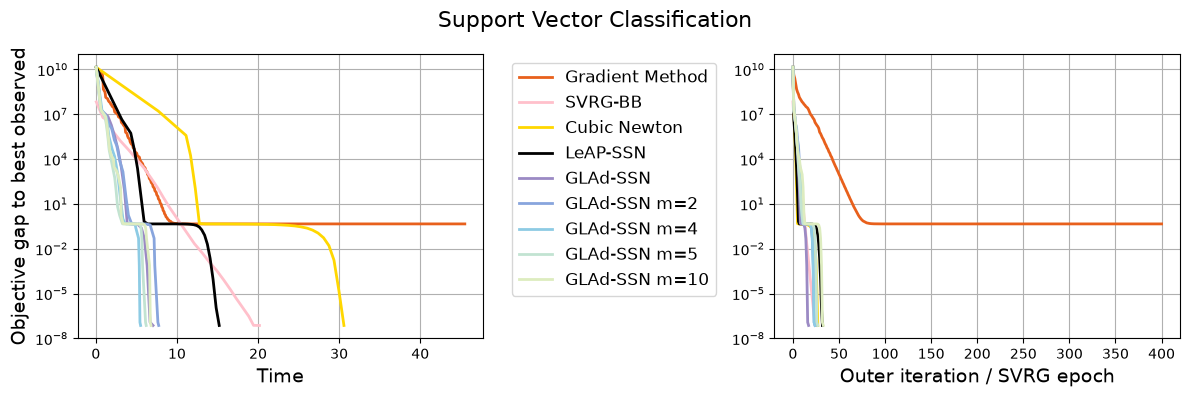

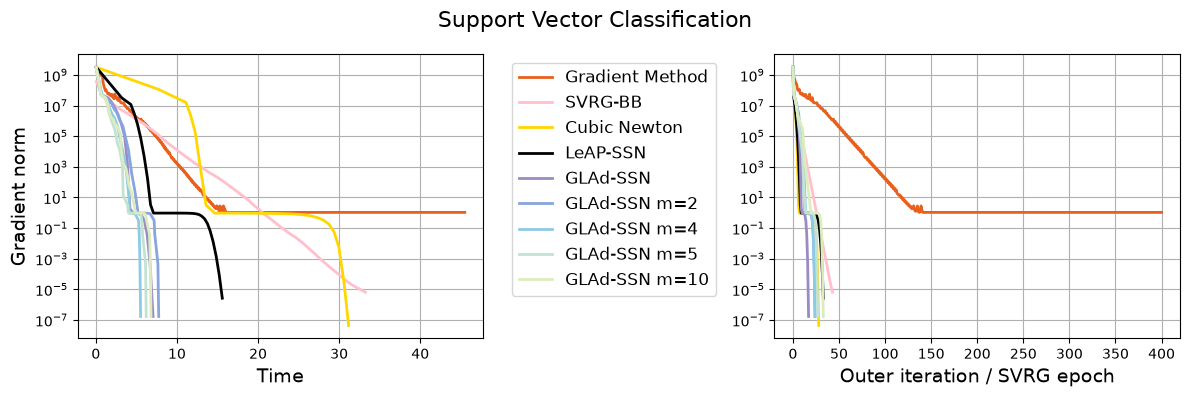

In [6]:

from SVM_utils_new import *
plot_figures(
    list(all_histories.values()),
    labels,
    colors=colors,
    linewidths=line_widths,
    linestyles=line_styles,
    n=N_FEATURES,
    m=None,
    mu_str=("0.5"),
    f_star=mn_func,
    threshold=1e-10,
    suptitle=("Support Vector Classification"),
    which_measure_2="func",
    max_iter=1000,
)

plot_figures(
    list(all_histories.values()),
    labels,
    colors=colors,
    linewidths=line_widths,
    linestyles=line_styles,
    n=N_FEATURES,
    m=None,
    mu_str=("0.5"),
    f_star=0,
    threshold=1e-10,
    suptitle=("Support Vector Classification"),
    max_iter=1000,
    which_measure_1="grad_norm",
    which_measure_2="grad_norm",
    ylabel="Gradient norm",
)



# Updated plot for the SVM comparison

Both panels use accepted outer iterates (SVRG-BB snapshots are epochs). This differs
from the original figure's trial-step axis. All methods appear in both panels;
the iteration panel retains the original 0--65 display window. Function gaps use
the best observed value across these runs, not a certified optimum. Values at the
scale-dependent floating-point floor are shown at that floor and then truncated.
Runtime is not clipped by default; set `clip_time=5` explicitly for the old layout.


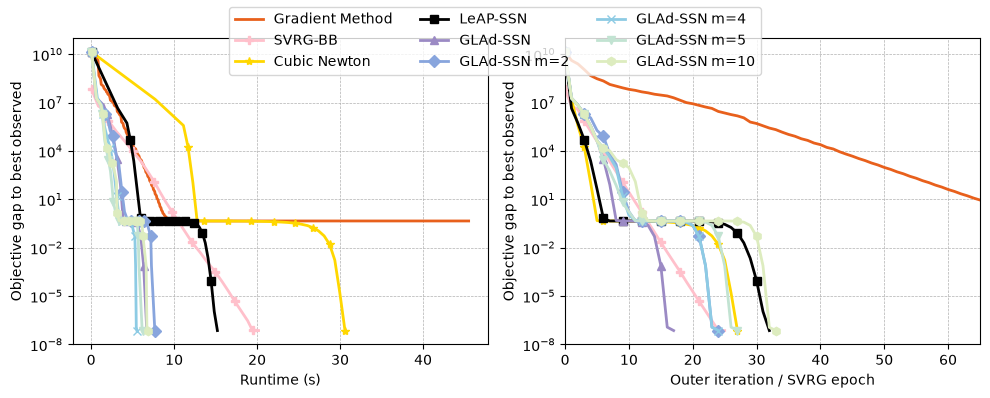

(<Figure size 1000x400 with 2 Axes>,
 array([<Axes: xlabel='Runtime (s)', ylabel='Objective gap to best observed'>,
        <Axes: xlabel='Outer iteration / SVRG epoch', ylabel='Objective gap to best observed'>],
       dtype=object))

In [7]:
m_cycle = [
"None",   # None Gradient Method
"P",   # plus-filled SVRG-BB
"*",   # star Cubic Newton
"s",   # square LeapSSN
"^",   # triangle up GladSSN
"D",   # diamond GladSSN second
"x",   # x GladSSN third
"v",   # triangle down GladSSN fourth
"h",   # hexagon GladSSN fifth
]
markevery_numbers = [3, 3, 3, 3, 3, 3, 3, 3, 3, 3]

import importlib
import SVM_utils_new
importlib.reload(SVM_utils_new)  # Pick up plot-style edits without rerunning the solvers.
from SVM_utils_new import plot_for_paper_2

plot_for_paper_2(
    list(all_histories.values()),
    labels,
    colors=colors,
    linewidths=line_widths,
    linestyles=line_styles,
    n=N_FEATURES,
    m=None,
    mu_str=("0.5"),
    f_star=mn_func,
    threshold=1e-10,
    suptitle=("Support Vector Classification"),
    max_iter=65,
    clip_time=None,  # Do not hide runtime on a different machine
    filename=RESULT_DIR / "plot_SVM_func_new.pdf",
    m_cycle=m_cycle,
    markevery_numbers=markevery_numbers

)

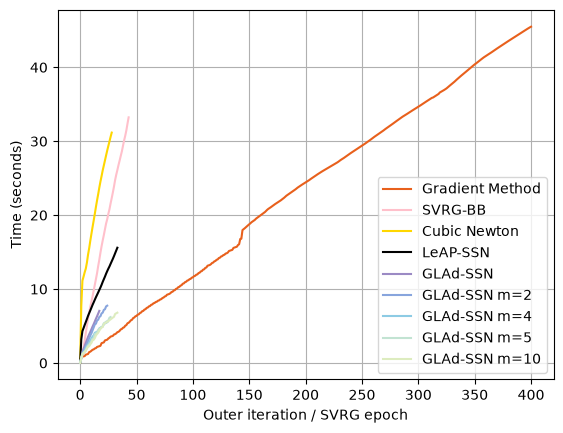

In [8]:
for label, (key, history), color in zip(labels, all_histories.items(), colors):
    times = history["time"]
    iters = range(len(times))
    plt.plot(iters, times, label=label, color=color)

plt.xlabel("Outer iteration / SVRG epoch")
plt.ylabel("Time (seconds)")
plt.legend()
plt.grid(True)
plt.show()